# **Who controls White's first-move advantage?**

In this notebook, we use the Chess Game Dataset from the Lichess server (public on Kaggle, CC0). It gives us about 20,000 online games with the result, the rating of both players, whether the game was rated, and every move that was played.

In chess White moves first, and in almost every collection of games White wins a bit more often than Black. We want to know how big this advantage really is once we take the strength of the players into account, and who controls it: White with the first move, or Black with the reply?

We answer it with a hierarchical Bayesian logistic regression, sampled with a Metropolis-within-Gibbs sampler that we wrote ourselves.

**How this notebook works:** it walks through how we did the work, but it never fits a model or simulates games itself. That part is heavy (we estimate about 3 hours on a 16-core machine for `python run_all.py`; we ran the scripts one at a time), so it is done by the scripts in this folder. Whenever a step needs a fit or simulated games, we name the script that did it, and the notebook reads the small table that this script saved in `tables/`. Every script has a fixed random seed, so running them again gives exactly the same tables. The `README.md` says which script makes which table.

Every number here is rounded with the same rule as in the report and its figures (`rounding.py`: halves rounded up), so a number reads the same everywhere; Part 12 checks that the numbers quoted here are those of the report.

1. We load the data and look at it
2. We check the quality of the data and clean it
3. We look at what drives the result: the rating gap and the opening
4. We define our final model and its priors
5. We explain how we arrived at this model, step by step
6. We describe the sampler we wrote
7. We check the sampler on simulated games, where we know the truth
8. We check that the sampler converged on the real games
9. We look at the results: first move, reply, ratings and players
10. We check the fit of the final model
11. We check how much the answers depend on our choices (priors and data)
12. We check that the numbers of the report match the code
13. Conclusion and limitations

## **IMPORTS**

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from rounding import fmt   # the rounding rule of the report and its figures

# colors and plot style
BLUE, ORANGE, INK, GREY = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110})

TABLES = "tables"   # where the scripts saved their results


def table(name):
    """Read one of the result tables saved by the scripts"""
    return pd.read_csv(os.path.join(TABLES, f"{name}.csv"))


def logistic(x):
    return 1 / (1 + np.exp(-x))


def rounded(values, digits, scale=1):
    """Round a table (or a column) for display exactly as the report rounds its numbers"""
    return values.map(lambda v: float(fmt(v, digits, scale).replace(",", ""))
                      if isinstance(v, float) and np.isfinite(v) else v)

# 1 - Loading the data

In [2]:
# the games are shipped with the code, download_data.py downloads them again only if they are missing
DATA = "data/raw/games.csv"
if not os.path.exists(DATA):
    %run download_data.py

In [3]:
games = pd.read_csv(DATA)

print("Number of rows:", games.shape[0])
print("Number of columns:", games.shape[1])
games.head()

Number of rows: 20058
Number of columns: 16


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
3,kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
4,9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5


**What we see:** 20,058 rows (one per game) and 16 columns. The ones we use are:

- `id`: the identifier of the game
- `rated`: whether the game counted for the ratings (True) or was a casual game (False)
- `turns`: the number of plies (one ply = one move of one player)
- `winner`: `white`, `black` or `draw`, **the target**
- `white_id`, `black_id`: the two players
- `white_rating`, `black_rating`: the rating of each player at the time of the game
- `moves`: every move of the game, from which we read White's first move and Black's reply
- `opening_eco`, `opening_name`: the opening code (ECO code) and its name

We do not use the time columns (`created_at`, `last_move_at`, `increment_code`) or `victory_status` (how the game ended).

# 2 - Check the quality of the data

Before we use the data, we check three problems:
- missing values;
- the same game written twice;
- games that were abandoned after a few moves rather than played.

We also have to decide what to do with draws.

In [4]:
print("Missing values in the whole table:", int(games.isna().sum().sum()))
print("Rows that are exact duplicates:", int(games.duplicated().sum()))
print("Rows whose game id was already seen:", int(games.duplicated("id").sum()))

Missing values in the whole table: 0
Rows that are exact duplicates: 429
Rows whose game id was already seen: 945


There are no missing values (nice!). However, 945 rows repeat a game id that we already have. Only 429 of them are exact copies, so the other repeats differ in some column, but it is still the same game, so we keep one row per game id.

We clean the data in three steps, in this order:
1. **one row per game id**;
2. **at least 10 plies**: under five moves per side, the game was abandoned, not played;
3. **decisive result**: we leave out the 855 draws (4.6% of the games). Our model is for a win or a loss, and the sensitivity analysis (part 11) scores the draws as half a win to check that this choice does not change the answers.

In [5]:
MIN_PLIES = 10

steps = [("raw file", games)]
steps.append(("one row per game id", steps[-1][1].drop_duplicates("id")))
steps.append((f"at least {MIN_PLIES} plies", steps[-1][1].query("turns >= @MIN_PLIES")))
steps.append(("decisive result (no draw)", steps[-1][1].query("winner != 'draw'")))

cleaning = pd.DataFrame({"step": [name for name, _ in steps], "games": [len(g) for _, g in steps]})
cleaning["removed"] = (-cleaning["games"].diff()).fillna(0).astype("int64")

# check: the same as the cleaning of prepare_data.py, which the models used
pd.testing.assert_frame_equal(cleaning, table("data_cleaning"))
cleaning

,step,games,removed
0,raw file,20058,0
1,one row per game id,19113,945
2,at least 10 plies,18537,576
3,decisive result (no draw),17682,855


We keep **17,682 decisive games**, and the check passes: our cleaning gives exactly the same table as `prepare_data.py`, the script that prepared the data for the models.

Now we build the variables of the model for each game:
- $y$ = 1 if White wins, 0 if Black wins;
- $\Delta$ = rating of White minus rating of Black, **divided by 400**. The Elo formula works on this scale: a gap of 400 points means that the stronger player is expected to score 10 times more than the weaker one;
- White's first move and Black's reply, read from the moves.

In [6]:
decisive = steps[-1][1].copy()
decisive["y"] = (decisive["winner"] == "white").astype(int)
decisive["gap"] = decisive["white_rating"] - decisive["black_rating"]     # in rating points
decisive["delta"] = decisive["gap"] / 400                                  # on the Elo scale
moves = decisive["moves"].str.split()
decisive["first_move"], decisive["reply"] = moves.str[0], moves.str[1]

players = pd.concat([decisive["white_id"], decisive["black_id"]])
print(f"White wins {fmt(decisive['y'].mean(), 1, 100)}% of the decisive games")
print(f"{fmt(decisive['rated'].mean(), 1, 100)}% of the games are rated")
print(f"{players.nunique():,} different players")
print(f"{fmt(((decisive.white_rating == 1500) | (decisive.black_rating == 1500)).mean(), 1, 100)}% of the games have a player rated exactly 1500 (the starting rating on Lichess)")

White wins 52.1% of the decisive games
81.4% of the games are rated
14,832 different players
7.3% of the games have a player rated exactly 1500 (the starting rating on Lichess)


# 3 - What drives the result?

Our question is about the opening, but the first thing that decides a game is of course the difference of strength between the two players. So we look at both.

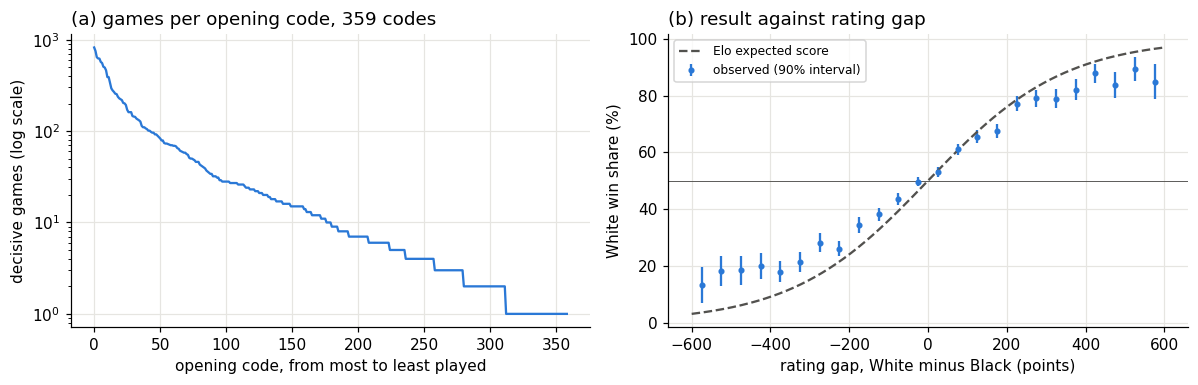

Median number of games per opening code: 10
Opening codes with only one game: 47


In [7]:
# (a) how many games per opening code, (b) White's win share against the rating gap
per_code = decisive["opening_eco"].value_counts()

bins = np.arange(-600, 601, 50)
decisive["gap_bin"] = pd.cut(decisive["gap"], bins)
by_gap = decisive.groupby("gap_bin", observed=True)["y"].agg(["mean", "count"])
by_gap = by_gap[by_gap["count"] >= 30]                        # leave out bins with very few games
centre = np.array([b.mid for b in by_gap.index])
half_width = 1.645 * np.sqrt(by_gap["mean"] * (1 - by_gap["mean"]) / by_gap["count"])   # 90% binomial interval

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(np.arange(len(per_code)), per_code.values, color=BLUE)
ax1.set_yscale("log")
ax1.set_xlabel("opening code, from most to least played")
ax1.set_ylabel("decisive games (log scale)")
ax1.set_title(f"(a) games per opening code, {len(per_code)} codes", loc="left")

ax2.errorbar(centre, 100 * by_gap["mean"], yerr=100 * half_width, fmt="o", ms=3, color=BLUE, label="observed (90% interval)")
x = np.linspace(-600, 600, 200)
ax2.plot(x, 100 / (1 + 10 ** (-x / 400)), color=GREY, ls="--", label="Elo expected score")
ax2.axhline(50, color=GREY, lw=0.6)
ax2.set_xlabel("rating gap, White minus Black (points)")
ax2.set_ylabel("White win share (%)")
ax2.set_title("(b) result against rating gap", loc="left")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Median number of games per opening code:", int(per_code.median()))
print("Opening codes with only one game:", int((per_code == 1).sum()))

**What we see:**

- (a) The opening codes are very unequal: the median code has only 10 games and 47 codes have a single game. If we estimated each opening on its own, most estimates would be pure noise. This is why we need a **hierarchical** model, which shares information between openings (partial pooling).
- (b) The rating gap clearly drives the result. But the curve is **flatter than the Elo formula**: the stronger player wins less often than Elo promises. And at a gap of 0, White wins a bit more than 50% of the games: this is the first-move advantage we want to measure.

In [8]:
# The opening is chosen by both players: White plays the first move, then Black replies
first = decisive.groupby("first_move")["y"].agg(games="count", white_win_share="mean")
first.sort_values("games", ascending=False).head(8).pipe(rounded, 3)

,games,white_win_share
first_move,,
e4,11121,0.526
d4,4073,0.526
c4,653,0.560
Nf3,597,0.559
e3,323,0.328
g3,159,0.484
b3,152,0.493
f4,129,0.504


In [9]:
after_e4 = decisive[decisive.first_move == "e4"].groupby("reply")["y"].agg(games="count", white_win_share="mean")
after_e4.sort_values("games", ascending=False).head(8).pipe(rounded, 3)

,games,white_win_share
reply,,
e5,5331,0.543
c5,2311,0.477
e6,1220,0.511
d5,705,0.528
c6,483,0.509
d6,300,0.577
Nc6,186,0.629
Nf6,184,0.538


1.e4 and 1.d4 are by far the most played first moves, and after 1.e4 the most common replies are 1...e5 and the Sicilian (1...c5).

One thing is important here: an **opening code mixes the moves of both players**. For example "B20 Sicilian Defense" is White's 1.e4 plus Black's 1...c5. So a model with one effect per opening code cannot tell us who controls the advantage. These raw win shares also do not take the ratings into account, which the model will do.

# 4 - The final model

We first present the model we ended with, and then in part 5 we explain how we arrived at it.

Game $i$ is played by White $w(i)$ against Black $b(i)$. White's first move is $m$ and Black's reply is $r$, and we call the pair $c = (m, r)$. The model is

$$y_i \sim \text{Bernoulli}\big(\text{logit}^{-1}(\eta_i)\big), \qquad \eta_i = \theta_{c(i)} + \beta_{g(i)}\,\Delta_i + u_{w(i)} - u_{b(i)}$$

$$\theta_c \sim \mathcal{N}(\gamma_{m(c)},\ \tau_r^{-1}), \qquad \gamma_m \sim \mathcal{N}(\mu,\ \tau_m^{-1}), \qquad u_p \sim \mathcal{N}(0,\ \tau_p^{-1})$$

where $\text{logit}^{-1}(x) = 1/(1 + e^{-x})$ turns a log-odds into a probability, and:

| Symbol | Meaning |
|---|---|
| $y_i$ | 1 if White wins game $i$, 0 if Black wins |
| $\Delta_i$ | rating of White minus rating of Black, divided by 400 |
| $g(i)$ | the group of the game: rated or unrated |
| $\beta_g$ | how much the rating gap changes the result, one slope per group |
| $\theta_c$ | White's advantage (log-odds) after the pair $c$, for two players of equal rating and average strength for their rating |
| $\gamma_m$ | White's advantage after first move $m$, averaged over Black's replies |
| $\mu$ | the average advantage over the 20 first moves |
| $u_p$ | how much stronger ($u_p > 0$) or weaker player $p$ is than their rating |
| $\tau_m, \tau_r, \tau_p$ | precisions of the three levels; we report the spreads $\sigma = \tau^{-1/2}$ |

So the model has two levels for the opening (first moves, then replies inside each first move), one effect per player, and the rating gap. The unknowns are $\beta_1, \beta_2, \mu$, the 3 precisions, 20 effects $\gamma_m$, 203 effects $\theta_c$ and 14,832 effects $u_p$.

### Priors

The priors are independent:
- $\mu \sim \mathcal{N}(0, 0.5^2)$: we have no idea of the sign of the advantage, and we let it be anything reasonable;
- $\beta_g \sim \mathcal{N}(\log 10,\ 1)$: centred on the Elo formula, whose expected score $1/(1 + 10^{-\text{gap}/400})$ is exactly $\text{logit}^{-1}(\log(10)\,\Delta)$. A standard deviation of 1 leaves the slope to the data, as Lichess ratings are Glicko-2 ratings, not Elo;
- $\tau_m, \tau_r, \tau_p \sim \text{Gamma}(1, 0.05)$ (shape, rate): conjugate to the Normal levels, which makes them easy to sample.

Let's check what these priors actually say on the scale we care about:

In [10]:
# mu: White's chance of winning at equal ratings, 95% of the prior
low, high = logistic(-1.96 * 0.5), logistic(1.96 * 0.5)
print(f"mu ~ N(0, 0.5^2): P(White wins) between {fmt(low, 0, 100)}% and {fmt(high, 0, 100)}% with 95% prior probability")

# beta: centred on the Elo slope
print(f"beta ~ N(log 10, 1): prior mean {fmt(np.log(10), 2)}")

# tau ~ Gamma(shape 1, rate 0.05): the spread sigma = tau^(-1/2) is small when tau is large
tau = stats.gamma(a=1, scale=1 / 0.05)
print(f"tau ~ Gamma(1, 0.05): spread between {fmt(tau.ppf(0.95) ** -0.5, 2)} and {fmt(tau.ppf(0.05) ** -0.5, 2)} with 90% prior probability")
print(f"   prior probability of a spread below 0.10: {fmt(tau.sf(0.10 ** -2), 2, 100)}%")

mu ~ N(0, 0.5^2): P(White wins) between 27% and 73% with 95% prior probability
beta ~ N(log 10, 1): prior mean 2.30
tau ~ Gamma(1, 0.05): spread between 0.13 and 0.99 with 90% prior probability
   prior probability of a spread below 0.10: 0.67%


The priors are wide on the scale of the question: White's chance at equal ratings can be anything between 27% and 73%. The prior on the spreads keeps them between 0.13 and 0.99 with 90% probability, but it puts **only 0.67% of its mass on a spread below 0.10**. Keep this in mind, it will come back in the validation (part 7).

**Our assumptions:**
- given the parameters, the games are independent;
- the rating gap acts linearly on the log-odds, inside each group;
- the opening and player effects do not depend on the rating level;
- players **choose** their openings, so the effects are associations (given the ratings and the player effects), not the effect of forcing someone to play a move.

# 5 - How we arrived at the final model

We did not start with this model. We started with the simplest one and **added a part only when the simpler model failed a check or could not answer our question**:

| Model | What it adds | Why |
|---|---|---|
| $M_0$ | one effect per opening code, one rating slope | starting point |
| $M_1$ | one rating slope for rated and one for unrated games | $M_0$ fails a posterior predictive check on the rating gap |
| $M_2$ | first move and reply instead of the opening code | an opening code cannot say who controls the advantage |
| $M_3$ (final) | one effect per player | the games of a player are not independent under $M_2$ |

A **posterior predictive check** works like this: we simulate many new data sets from the fitted model, compute a statistic on each of them, and compare with the same statistic on the real games. If the real value is in the tail of the simulated ones (a $p$-value close to 0 or 1), the model misses something.

Each model was validated on simulated games before being fitted (part 7).

## 5.1 - $M_0$: one effect per opening code

$\Pr(y_i = 1) = \text{logit}^{-1}(\theta_{o(i)} + \beta\,\Delta_i)$, with one effect $\theta_o \sim \mathcal{N}(\mu, \sigma^2)$ for each of the 359 opening codes (script `fit_real.py`).

In [11]:
table("posterior_shared").set_index("quantity")[["mean", "q05", "q95"]].pipe(rounded, 3)

,mean,q05,q95
quantity,,,
beta,1.530,1.472,1.589
mu,0.090,0.053,0.126
sigma,0.143,0.109,0.181
white advantage in rating points (400 mu / beta),23.470,13.922,33.097
"P(white wins) at equal ratings, average opening",0.522,0.513,0.532


$M_0$ already gives a clear first-move advantage: 23.5 rating points (13.9 to 33.1), so White wins 52.2% of the decisive games at equal ratings. But does the model reproduce the data? The posterior predictive check was done by `posterior_predictive.py`, from 4,000 data sets simulated from the posterior of $M_0$.

In [12]:
check_M0 = table("posterior_predictive").set_index("statistic")
check_M0[["observed", "replicated_q05", "replicated_q95", "p_value"]].pipe(rounded, 3)

,observed,replicated_q05,replicated_q95,p_value
statistic,,,,
"white win share, all games",0.521,0.513,0.529,0.512
sd of white win share between openings with at least 30 games,0.080,0.065,0.084,0.151
"white win share, rating gap -1605 to -274",0.189,0.159,0.194,0.116
"white win share, rating gap -274 to -146",0.307,0.310,0.351,0.976
"white win share, rating gap -146 to -76",0.397,0.393,0.435,0.904
"white win share, rating gap -76 to -29",0.468,0.449,0.490,0.549
"white win share, rating gap -29 to 3",0.501,0.487,0.527,0.699
"white win share, rating gap 3 to 39",0.533,0.517,0.558,0.656
"white win share, rating gap 39 to 88",0.588,0.559,0.600,0.272


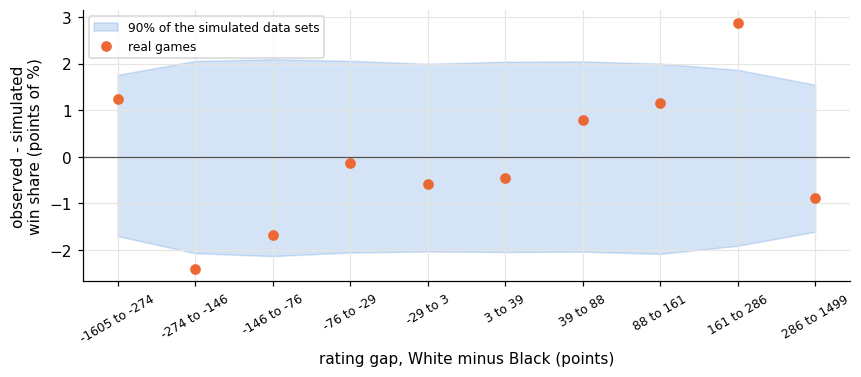

In [13]:
# observed win share minus the simulated one, in each decile of rating gap
gap_rows = check_M0[check_M0.index.str.startswith("white win share, rating gap")]
labels = gap_rows.index.str.replace("white win share, rating gap ", "")
diff = 100 * (gap_rows["observed"] - gap_rows["replicated_mean"])
low = 100 * (gap_rows["replicated_q05"] - gap_rows["replicated_mean"])
high = 100 * (gap_rows["replicated_q95"] - gap_rows["replicated_mean"])

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.fill_between(range(len(gap_rows)), low, high, color=BLUE, alpha=0.2, label="90% of the simulated data sets")
ax.plot(range(len(gap_rows)), diff, "o", color=ORANGE, label="real games")
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xticks(range(len(gap_rows)), labels, rotation=30, fontsize=8)
ax.set_xlabel("rating gap, White minus Black (points)")
ax.set_ylabel("observed - simulated\nwin share (points of %)")
ax.legend(fontsize=8)
plt.show()

$M_0$ reproduces the overall win share ($p = 0.51$) and the spread between openings ($p = 0.15$), but **not the shape of the win share against the rating gap**: the chi-square discrepancy over the deciles has $p = 0.026$. For example, for gaps of 161 to 286 points, White wins 74.1% of the games, against 71.2% in the simulated data.

So one slope for all games is not enough.

## 5.2 - $M_1$: one slope for rated and one for unrated games

Rated and casual games are quite different: in a casual game, players often try things or do not play seriously. So we gave each group its own slope $\beta_g$ (script `fit_rating_slopes.py`).

In [14]:
table("posterior_rating_slopes").set_index("quantity")[["mean", "q05", "q95"]].pipe(rounded, 3)

,mean,q05,q95
quantity,,,
"beta, rated games",1.736,1.664,1.809
"beta, unrated games",1.103,1.011,1.197
"beta, rated minus unrated",0.633,0.515,0.750
mu,0.090,0.054,0.127
sigma,0.140,0.106,0.179
"white advantage in rating points, rated games (400 mu / beta)",20.831,12.364,29.310


In [15]:
# p-values of the rating-gap check, with one slope and with two
check_M1 = table("posterior_predictive_rating_slopes")
check_M1 = check_M1[check_M1.statistic.str.startswith("chi-square")]
check_M1.pivot(index="statistic", columns="model", values="p_value").pipe(rounded, 3)

model,one slope,rated and unrated slopes
statistic,,
"chi-square over deciles of rating gap, all games",0.027,0.331
"chi-square over deciles of rating gap, rated games",0.006,0.765
"chi-square over deciles of rating gap, unrated games",0.000,0.224


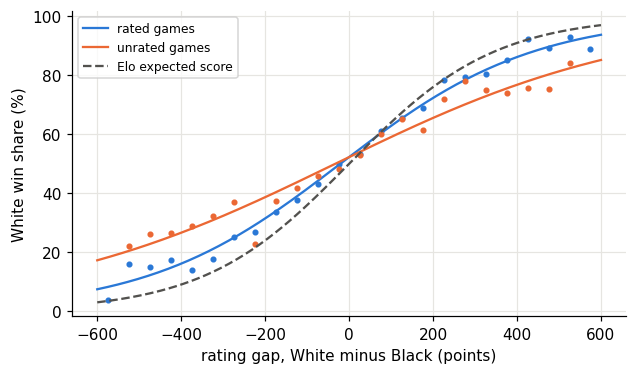

In [16]:
# the two slopes against the data, with the Elo formula
slopes = table("posterior_rating_slopes").set_index("quantity")["mean"]
x = np.linspace(-600, 600, 200)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for rated, name, colour in ((True, "rated games", BLUE), (False, "unrated games", ORANGE)):
    d = decisive[decisive.rated == rated].groupby("gap_bin", observed=True)["y"].agg(["mean", "count"])
    d = d[d["count"] >= 30]
    ax.plot([b.mid for b in d.index], 100 * d["mean"], "o", ms=3, color=colour)
    ax.plot(x, 100 * logistic(slopes["mu"] + slopes[f"beta, {name}"] * x / 400), color=colour, label=name)
ax.plot(x, 100 / (1 + 10 ** (-x / 400)), color=GREY, ls="--", label="Elo expected score")
ax.set_xlabel("rating gap, White minus Black (points)")
ax.set_ylabel("White win share (%)")
ax.legend(fontsize=8)
plt.show()

With two slopes the check passes ($p = 0.331$ over all games), and also inside each group, where one slope failed badly ($p = 0.006$ for rated and $p < 0.001$ for unrated games). The rating gap matters much more in rated games (1.74) than in casual ones (1.10), and both slopes are below the Elo slope ($\log 10 = 2.30$): ratings predict the result less well than the Elo formula promises.

## 5.3 - $M_2$: White's first move and Black's reply

This step was not forced by a failed check, but by our question. As we saw in part 3, an opening code mixes the moves of both players, so it cannot say who controls the advantage. So we replaced the opening code by the pair $c = (m, r)$ of White's first move and Black's reply, each chosen by one player alone, in the two-level hierarchy of part 4: first moves around $\mu$, then replies around their first move.

This model is the final model without the player effects. Its sampler is `sampler_moves.py`, and `fit_moves.py` fitted it to the real games; we use its draws in the next step.

## 5.4 - $M_3$: one effect per player

Many players appear in several games. If some players are stronger, or weaker, than their rating, their games are not independent given $M_2$. To check this, for every player with at least 10 games, we compare their score with the score that the model expects, and standardise the difference. If the model is right, the variance of these standardised differences should be about 1.

This check was done by `posterior_predictive_full.py`: for 4,000 posterior draws of $M_2$ (from `fit_moves.py`) and of the final model (from `fit_full.py`), it simulated the results of the real games and computed this variance on the real and on the simulated results.

In [17]:
check_players = table("posterior_predictive_full")
check_players = check_players[check_players.statistic.str.startswith("player dispersion")]
check_players.set_index("model")[["observed", "replicated_q05", "replicated_q95", "p_value"]].pipe(rounded, 3)

,observed,replicated_q05,replicated_q95,p_value
model,,,,
without player effects,2.143,0.909,1.095,0.000
with player effects,1.057,0.909,1.096,0.231


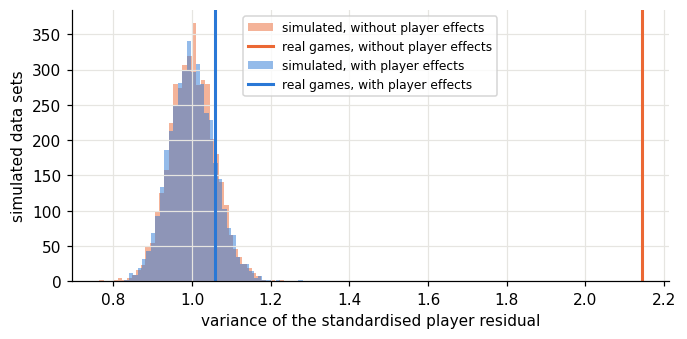

In [18]:
replicates = table("posterior_predictive_full_replicates")

fig, ax = plt.subplots(figsize=(7, 3.2))
for model, colour in (("without player effects", ORANGE), ("with player effects", BLUE)):
    ax.hist(replicates[f"{model}, replicated"], bins=40, color=colour, alpha=0.5, label=f"simulated, {model}")
    ax.axvline(replicates[f"{model}, observed"].mean(), color=colour, lw=2, label=f"real games, {model}")
ax.set_xlabel("variance of the standardised player residual")
ax.set_ylabel("simulated data sets")
ax.legend(fontsize=8)
plt.show()

Without player effects, the real variance is **2.14**, while the simulated data sets give between 0.91 and 1.10 ($p < 0.001$): the same players keep beating, or missing, their rating. With one effect per player, the real value drops to 1.06, right inside the simulated ones ($p = 0.23$).

This is the final model of part 4.

# 6 - The sampler

The posterior has no closed form, so we sample it with a **Metropolis-within-Gibbs** sampler that we wrote in Python with NumPy (`sampler_full.py`). One iteration:

1. update every $\theta_c$ with a random-walk Metropolis-Hastings step;
2. a **rescaling move** for the replies (explained below);
3. update $\beta_1, \beta_2$ with random-walk Metropolis-Hastings;
4. update the player effects $u_p$ with random-walk Metropolis-Hastings, by batches;
5. a rescaling move for the players;
6. draw each $\gamma_m$, then $\mu$, from their Normal full conditionals, and $\tau_r, \tau_m, \tau_p$ from their Gamma full conditionals (conjugate, so no accept step).

$\theta_c$, $\beta_g$ and $u_p$ contain the logistic likelihood, so they have no standard full conditional: this is why they get Metropolis-Hastings steps. Given the rest, the pairs are independent of each other, so all of them move in one vectorised sweep, with one accept step per pair.

**Players by batches:** two players who met share a game, so they are not independent. We split the players into groups that never played each other (a "colouring" of the graph whose edges are the games: 4 groups are enough). Inside a group the players are independent given the rest, so they all move at once.

In [19]:
# How many games does each player have?
player_table = table("posterior_full_players")
games_per_player = player_table["games"].value_counts().sort_index()
print(games_per_player.head(5))
print(f"Players with 1 or 2 games: {fmt((player_table.games <= 2).mean(), 0, 100)}%")
print(f"Players with at least 10 games: {(player_table.games >= 10).sum()}")

games
1    11149
2     1885
3      571
4      214
5      130
Name: count, dtype: int64
Players with 1 or 2 games: 88%
Players with at least 10 games: 626


**Rescaling moves:** 88% of the players have only 1 or 2 games, so the data say very little about each $u_p$. Each $u_p$ is then held near the current spread $\sigma_p$, and $\sigma_p$ is held near the current $u_p$: updating them one at a time, the sampler crawls along this "funnel". In a first version, the player spread had an effective sample size of 6 out of 20,000 draws on simulated data!

So we added a move that changes a whole level and its precision together: $u' = e^{\varepsilon} u$ and $\tau_p' = e^{-2\varepsilon}\tau_p$, with $\varepsilon \sim \mathcal{N}(0, s^2)$. It is a Metropolis-Hastings step with a deterministic transformation, so its acceptance probability needs the Jacobian of the transformation; the derivation is in Appendix A of the report. With it, the same quantity reached an effective sample size of 399.

**Tuning and runs:** each proposal scale is 2.38 posterior standard deviations (Roberts, Gelman and Gilks, 1997), estimated on a 3,000-iteration pilot run. We run 4 chains from starting points drawn from the prior, throw away the first 2,000 iterations (burn-in) and keep 40,000 per chain. This is what `fit_full.py` did; it saved the acceptance rates and the convergence diagnostics in `tables/sampler_diagnostics_full.csv`.

In [20]:
diagnostics = table("sampler_diagnostics_full").set_index("statistic")["value"]
diagnostics[diagnostics.index.str.contains("acceptance")]

statistic
acceptance rate of beta (rated, unrated)                          [0.41, 0.411]
median acceptance rate of theta                             0.35755000000000003
median acceptance rate of the player effects                0.44351874999999996
lowest and highest acceptance rate of the player effects         [0.382, 0.501]
Name: value, dtype: str

Every Metropolis-Hastings step updates one number at a time, and for such one-dimensional random-walk steps the usual target acceptance rate is around 0.44. Our median rates (0.36 for the pairs, 0.44 for the players, 0.41 for the slopes) are close to it, so the proposal scales are sensible.

# 7 - Validation on simulated games

Before using a sampler on the real games, we need to know that it works. So we simulate games **from the model itself**, with the real rating gaps, groups, openings and players, and parameter values that we know. If the sampler is correct, it should find them again. We did this for every model, with two tests (scripts `validate_*.py`):

1. **One data set with values we choose:** the true values should fall in the 90% posterior intervals most of the time.
2. **Coverage over 100 data sets whose parameters are drawn from the prior:** if the sampler is correct, the 90% intervals contain the truth 90% of the time, and the 50% intervals 50% of the time, on average over the prior. This holds whatever the prior is, so it is the real test of the sampler.

In [21]:
models = [("M0: opening codes", "validation_recovery", "validation_coverage"),
          ("M1: + two slopes", "validation_rating_slopes_recovery", "validation_rating_slopes_coverage"),
          ("M2: first move and reply", "validation_moves_recovery", "validation_moves_coverage"),
          ("M3: final, + players", "validation_full_recovery", "validation_full_coverage")]
rows = {}
for name, recovery_name, coverage_name in models:
    recovery = table(recovery_name)
    recovery = recovery[~recovery["quantity"].str.contains("minus")]   # differences are not parameters
    coverage = table(coverage_name)
    rows[name] = {"true values inside 90% interval": f"{int(recovery['inside_90'].sum())} of {len(recovery)}",
                  "coverage of 50% intervals": f"{fmt(coverage['coverage_50'].min(), 0, 100)}% to {fmt(coverage['coverage_50'].max(), 0, 100)}%",
                  "coverage of 90% intervals": f"{fmt(coverage['coverage_90'].min(), 0, 100)}% to {fmt(coverage['coverage_90'].max(), 0, 100)}%"}
pd.DataFrame(rows).T

,true values inside 90% interval,coverage of 50% intervals,coverage of 90% intervals
M0: opening codes,2 of 3,46% to 58%,90% to 94%
M1: + two slopes,4 of 4,45% to 52%,86% to 93%
M2: first move and reply,5 of 5,48% to 56%,87% to 90%
"M3: final, + players",3 of 6,48% to 54%,84% to 94%


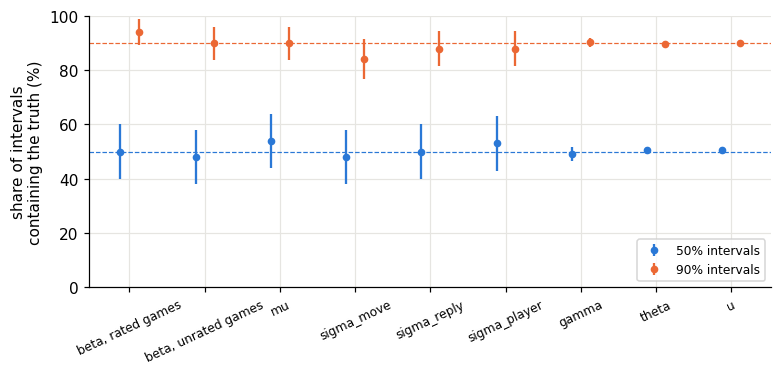

In [22]:
# coverage of the final model, for each parameter, with +/- 2 standard errors
coverage = table("validation_full_coverage")
x = np.arange(len(coverage))

fig, ax = plt.subplots(figsize=(8, 3.2))
for offset, level, colour in ((-0.12, 50, BLUE), (0.12, 90, ORANGE)):
    ax.axhline(level, color=colour, ls="--", lw=0.8)
    ax.errorbar(x + offset, 100 * coverage[f"coverage_{level}"], yerr=200 * coverage[f"se_{level}"],
                fmt="o", ms=4, color=colour, label=f"{level}% intervals")
ax.set_xticks(x, coverage["quantity"], fontsize=8, rotation=25)
ax.set_ylim(0, 100)
ax.set_ylabel("share of intervals\ncontaining the truth (%)")
ax.legend(fontsize=8, loc="lower right")
plt.show()

For every parameter of every model, the coverage matches the nominal level within its standard errors, including the 203 pairs and the 14,832 player effects of the final model (where the share is over all pairs or players of all 100 data sets). So the sampler finds the posterior correctly.

Now the test with values we chose for the final model:

In [23]:
recovery_full = table("validation_full_recovery")
recovery_full[["quantity", "truth", "realized", "q05", "mean", "q95", "inside_90", "realized_inside_90"]].pipe(rounded, 3)

,quantity,truth,realized,q05,mean,q95,inside_90,realized_inside_90
0,"beta, rated games",1.95,NaN,1.899,1.985,2.074,True,False
1,"beta, unrated games",1.25,NaN,1.260,1.373,1.486,False,False
2,mu,0.08,0.018,-0.168,-0.063,0.043,False,True
3,sigma_move,0.15,0.147,0.101,0.162,0.247,True,True
4,sigma_reply,0.10,0.104,0.103,0.143,0.195,False,True
5,sigma_player,0.40,0.398,0.354,0.402,0.449,True,True


Here 3 of the 6 true values fall outside their 90% interval, which is a lot. Is it bad luck or a bias? $\mu$ and the spreads describe effects drawn once per data set (only 20 first moves for example), so the posterior targets the values **realised** in this data set (column `realized`). To separate chance from bias, `validate_full.py` refitted 40 data sets simulated with the same chosen values:

In [24]:
table("validation_full_repeated").pipe(rounded, 3)

,quantity,truth,share_inside_90,mean_error,se_mean_error
0,"beta, rated games",1.95,0.925,-0.001,0.007
1,"beta, unrated games",1.25,0.850,0.019,0.012
2,mu,0.08,0.950,0.008,0.009
3,sigma_move,0.15,0.900,0.040,0.006
4,sigma_reply,0.10,0.450,0.049,0.002
5,sigma_player,0.40,0.850,-0.001,0.005


The slopes, $\mu$ and the player spread show no bias, so their misses were chance. But the spread between replies $\sigma_r$ **is biased**: it is overestimated by 0.049 on average (standard error 0.002), and its interval contains the truth only 45% of the time. $\sigma_m$ is also overestimated, by 0.040.

The reason is the prior we saw in part 4: Gamma(1, 0.05) puts only 0.67% of its mass on a spread as small as the chosen 0.10, and with few games per pair the data cannot fully override it. So **the spreads between openings that we report lean high**. This does not contradict the coverage test, which averages over spreads drawn from the prior itself.

### Extra checks on the first model

On $M_0$, which is small enough, we also compared our sampler with three other methods: an exact grid integration on a small problem (`check_sampler.py`), importance sampling with a Laplace proposal on the model without openings (`check_importance_sampling.py`), and PyMC, only as a cross-check (`crosscheck_pymc.py`). The column `z` is the difference between the two methods, in Monte Carlo standard errors.

In [25]:
grid = table("check_quadrature")[["quantity", "mcmc_mean", "grid_mean", "z"]]
importance = table("check_importance_sampling")[["quantity", "mh_mean", "is_mean", "z_mean", "is_weight_ess"]]
pymc = table("crosscheck_pymc").dropna(subset=["our_mean"])[["quantity", "our_mean", "pymc_mean", "z_mean"]]
print("Grid integration:"); print(grid.pipe(rounded, 3).to_string(index=False)); print()
print("Importance sampling:"); print(importance.pipe(rounded, 3).to_string(index=False)); print()
print("PyMC:"); print(pymc.pipe(rounded, 3).to_string(index=False))

Grid integration:
quantity  mcmc_mean  grid_mean      z
    beta      2.263      2.263 -0.158
      mu     -0.003     -0.004  1.041
   sigma      0.634      0.634  0.195
theta[0]      0.719      0.717  0.773
theta[1]     -0.407     -0.407 -0.015
theta[2]     -0.423     -0.425  0.689

Importance sampling:
quantity  mh_mean  is_mean  z_mean  is_weight_ess
   alpha    0.075    0.075  -0.741      49987.497
    beta    1.544    1.544   0.281      49987.497

PyMC:
quantity  our_mean  pymc_mean  z_mean
    beta     1.530      1.530  -0.496
      mu     0.090      0.089   1.264
   sigma     0.143      0.142   0.806


All three agree with our sampler within about 2 Monte Carlo standard errors, so the differences are just Monte Carlo noise.

# 8 - Convergence on the real games

On the real games we do not know the truth, so we check that the 4 chains, started from different points drawn from the prior, end up in the same place. The traces were saved by `export_traces.py` from the draws of `fit_full.py`.

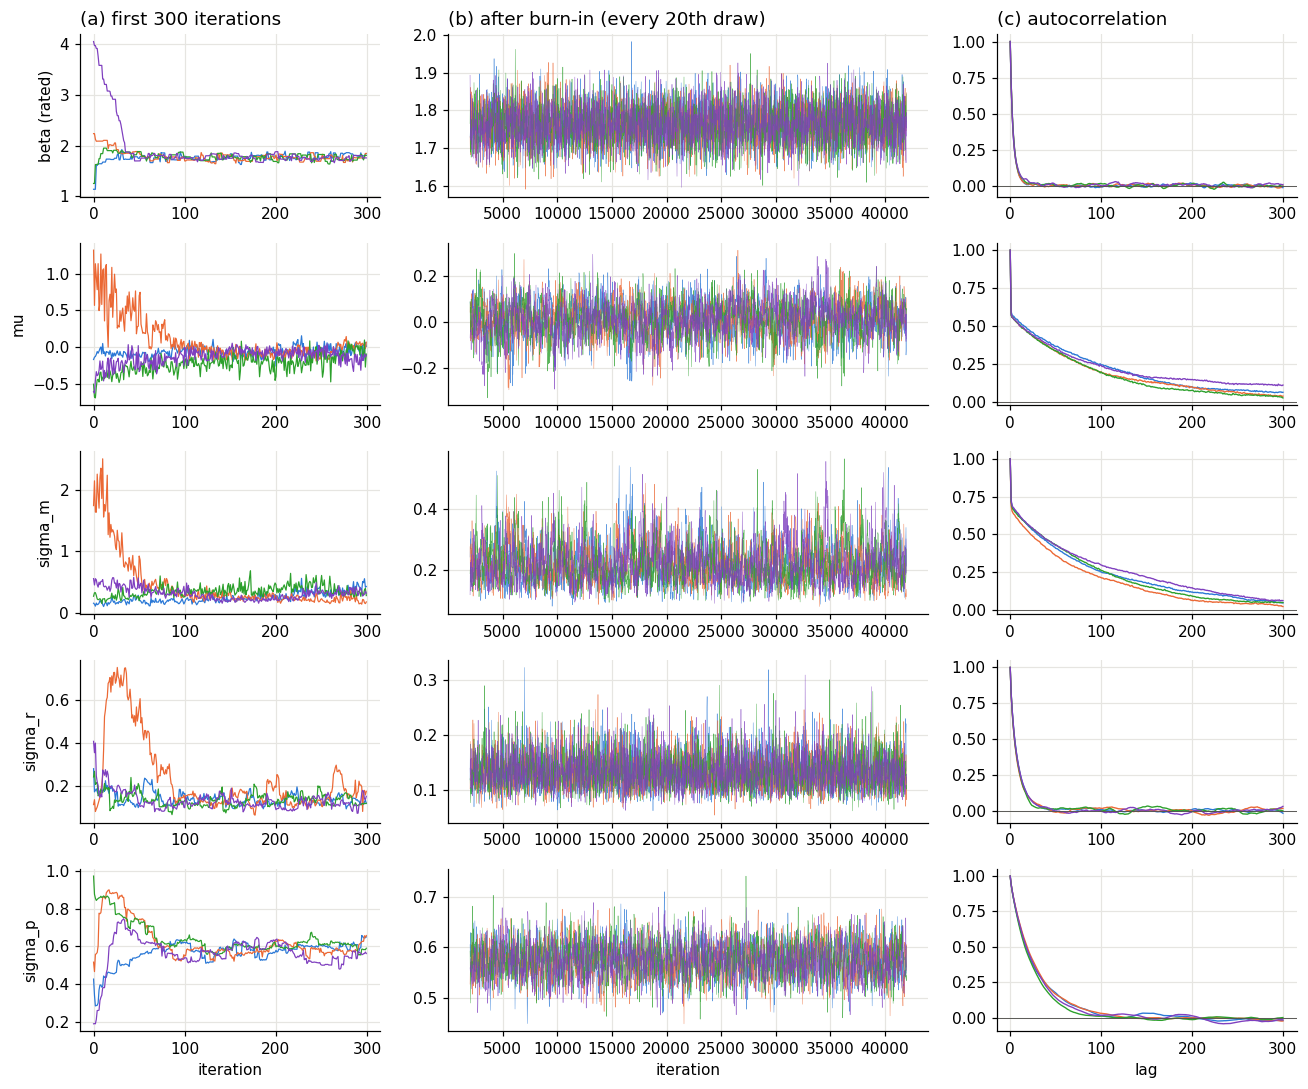

In [26]:
traces = table("trace_full")
autocorrelation = table("autocorrelation_full")
names = {"beta": "beta (rated)", "mu": "mu", "sigma_move": "sigma_m", "sigma_reply": "sigma_r", "sigma_player": "sigma_p"}
COLOURS = [BLUE, ORANGE, "#2ca02c", "#7f3fbf"]   # one colour per chain

fig, axes = plt.subplots(len(names), 3, figsize=(12, 10), gridspec_kw={"width_ratios": [1, 1.6, 1]})
for row, (name, label) in enumerate(names.items()):
    for c in range(1, 5):
        t = traces[(traces.parameter == name) & (traces.chain == c)]
        burn, kept = t[t.phase == "burn-in"], t[t.phase == "kept"]
        axes[row, 0].plot(burn.iteration, burn.value, lw=0.8, color=COLOURS[c - 1])
        axes[row, 1].plot(kept.iteration, kept.value, lw=0.3, alpha=0.8, color=COLOURS[c - 1])
        a = autocorrelation[(autocorrelation.parameter == name) & (autocorrelation.chain == c)]
        axes[row, 2].plot(a.lag, a.autocorrelation, lw=0.9, color=COLOURS[c - 1])
    axes[row, 0].set_ylabel(label)
    axes[row, 2].axhline(0, color=GREY, lw=0.6)
axes[0, 0].set_title("(a) first 300 iterations", loc="left")
axes[0, 1].set_title("(b) after burn-in (every 20th draw)", loc="left")
axes[0, 2].set_title("(c) autocorrelation", loc="left")
axes[-1, 0].set_xlabel("iteration")
axes[-1, 1].set_xlabel("iteration")
axes[-1, 2].set_xlabel("lag")
plt.tight_layout()
plt.show()

**What we see:**
- (a) The chains start far apart and meet within the first 300 iterations, long before the end of the burn-in of 2,000.
- (b) After burn-in, the 4 chains overlap completely.
- (c) The slope mixes very fast. $\mu$ and $\sigma_m$ are the most autocorrelated, which makes sense: they are learned from only 20 first moves, and they have no rescaling move.

To put numbers on it, we look at the split-$\hat R$ (close to 1 when the chains agree) and the effective sample size (ESS: how many independent draws the chains are worth). The Monte Carlo standard error (MCSE) should be small next to the posterior standard deviation (sd).

In [27]:
shared = table("posterior_full_shared").set_index("quantity")
shared["mcse / sd"] = shared["mcse"] / shared["sd"]
shared[["sd", "rhat", "ess", "mcse", "mcse / sd"]].pipe(rounded, 4)

,sd,rhat,ess,mcse,mcse / sd
quantity,,,,,
"beta, rated games",0.0521,1.0002,20385.5460,0.0004,0.0070
"beta, unrated games",0.0706,1.0006,17817.2502,0.0005,0.0075
"beta, rated minus unrated",0.0852,1.0004,22766.3716,0.0006,0.0066
mu (average over the 20 first moves),0.0780,1.0048,1182.7476,0.0023,0.0291
sigma_move (spread between White's first moves),0.0670,1.0025,1113.8237,0.0020,0.0300
sigma_reply (spread between Black's replies to one first move),0.0313,1.0003,10093.9942,0.0003,0.0100
sigma_player (spread between players at equal rating),0.0339,1.0022,3070.9474,0.0006,0.0180
sigma_move minus sigma_reply,0.0737,1.0017,1342.3594,0.0020,0.0273
"sigma_player in rating points, rated games (400 sigma_player / beta)",8.0624,1.0022,3845.2015,0.1300,0.0161


In [28]:
diagnostics[~diagnostics.index.str.contains("acceptance")]

statistic
largest split-Rhat, shared parameters                                       1.0048438389310896
smallest ESS, shared parameters                                             1113.8237023784484
largest split-Rhat, first moves                                               1.00717678335095
smallest ESS, first moves                                                    852.4229037418419
largest split-Rhat, pairs                                                     1.00523980602282
smallest ESS, pairs                                                         1096.1100892014388
largest split-Rhat, players with at least 10 games (draws kept every 40)    1.0026685421212662
smallest ESS, players with at least 10 games (draws kept every 40)           2553.918449194735
Name: value, dtype: str

The largest split-$\hat R$ over the shared parameters, first moves, pairs and players with at least 10 games is 1.007, and the smallest ESS is 852 (for a first move). The Monte Carlo standard errors are at most 3% of the posterior standard deviations, so the numbers we report are not driven by Monte Carlo noise.

# 9 - Results

All the results are for two players of **equal rating and average strength for their rating**, and are posterior means with 90% intervals. They come from the draws of `fit_full.py`, which saved them in `tables/posterior_full_*.csv`.

## 9.1 - White's first move

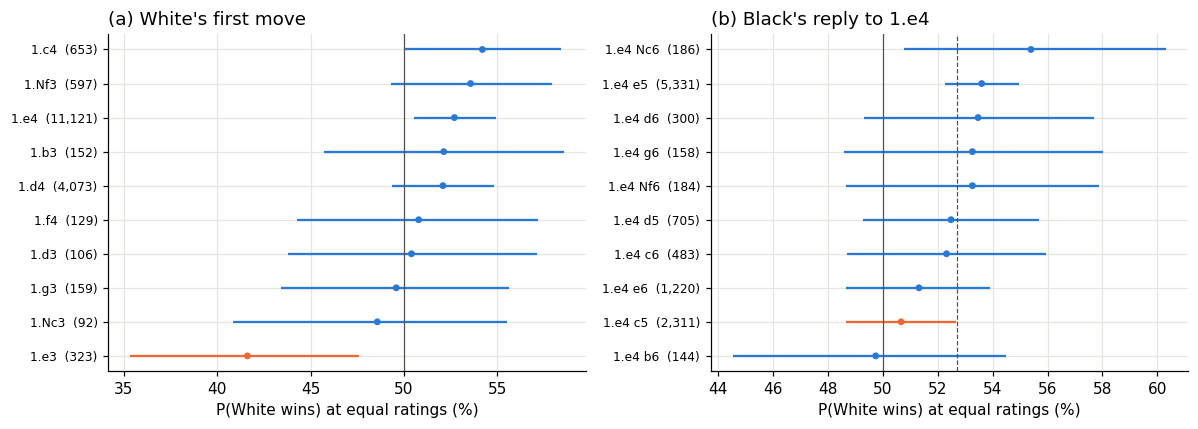

In [29]:
first_moves = table("posterior_full_first_moves")
first_moves = first_moves[first_moves.games >= 90].sort_values("p_white_equal_ratings_mean")
replies = table("posterior_full_replies")
e4_replies = replies[(replies.first_move == "e4") & (replies.games >= 140)].sort_values("p_white_equal_ratings_mean")
e4_average = shared.loc["P(white wins) at equal ratings after 1.e4", "mean"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for ax, d, label, special in ((ax1, first_moves, "1." + first_moves.first_move, "e3"),
                              (ax2, e4_replies, "1.e4 " + e4_replies.reply, "c5")):
    mean = 100 * d.p_white_equal_ratings_mean
    error = [mean - 100 * d.p_white_equal_ratings_q05, 100 * d.p_white_equal_ratings_q95 - mean]
    colour = [ORANGE if s == special else BLUE for s in (d.first_move if ax is ax1 else d.reply)]
    ax.errorbar(mean, range(len(d)), xerr=error, fmt="none", ecolor=colour)
    ax.scatter(mean, range(len(d)), color=colour, s=12, zorder=3)
    ax.set_yticks(range(len(d)), [f"{l}  ({n:,})" for l, n in zip(label, d.games)], fontsize=8)
    ax.axvline(50, color=GREY, lw=0.8)
    ax.set_xlabel("P(White wins) at equal ratings (%)")
ax1.set_title("(a) White's first move", loc="left")
ax2.set_title("(b) Black's reply to 1.e4", loc="left")
ax2.axvline(100 * e4_average, color=GREY, ls="--", lw=0.8)
plt.tight_layout()
plt.show()

In [30]:
show = {"first_move": "first move", "games": "games", "p_white_equal_ratings_mean": "P(White wins)",
        "p_white_equal_ratings_q05": "q05", "p_white_equal_ratings_q95": "q95", "prob_above_average": "P(above average)"}
first_moves.sort_values("games", ascending=False)[list(show)].rename(columns=show).pipe(rounded, 3)

,first move,games,P(White wins),q05,q95,P(above average)
0,e4,11121,0.527,0.505,0.549,0.862
1,d4,4073,0.521,0.494,0.548,0.774
2,c4,653,0.542,0.501,0.584,0.910
3,Nf3,597,0.536,0.493,0.579,0.864
4,e3,323,0.416,0.353,0.476,0.006
5,g3,159,0.496,0.434,0.556,0.425
6,b3,152,0.521,0.457,0.586,0.679
7,f4,129,0.508,0.443,0.572,0.545
8,d3,106,0.504,0.438,0.571,0.505
9,Nc3,92,0.486,0.409,0.555,0.351


At equal ratings White wins **52.7%** of the decisive games after 1.e4 (50.5% to 54.9%), and 52.1% after 1.d4. In rating points, 1.e4 is worth **24.5 points** to White (4.8 to 44.9), positive with probability 0.979.

White's first move matters: after **1.e3** White wins only **41.6%** (35.3% to 47.6%), so this first move throws the advantage away, while 1.c4 gives the most, 54.2%.

## 9.2 - Black's reply to 1.e4

In [31]:
show = {"reply": "reply", "games": "games", "p_white_equal_ratings_mean": "P(White wins)",
        "p_white_equal_ratings_q05": "q05", "p_white_equal_ratings_q95": "q95",
        "prob_below_compared": "P(better for Black than 1...e5)"}
e4_replies.sort_values("games", ascending=False)[list(show)].rename(columns=show).pipe(rounded, 3)

,reply,games,P(White wins),q05,q95,P(better for Black than 1...e5)
136,e5,5331,0.536,0.523,0.549,0.000
137,c5,2311,0.507,0.487,0.527,0.978
138,e6,1220,0.513,0.487,0.539,0.902
139,d5,705,0.525,0.493,0.557,0.707
140,c6,483,0.523,0.487,0.559,0.710
141,d6,300,0.535,0.493,0.577,0.523
142,Nc6,186,0.554,0.508,0.603,0.276
143,Nf6,184,0.533,0.487,0.579,0.549
144,g6,158,0.533,0.486,0.580,0.548
145,b6,144,0.497,0.445,0.545,0.899


Black's reply matters too. Against 1.e4, the **Sicilian (1...c5) leaves White only 50.7%** (48.7% to 52.7%), an interval that contains 50%: Black almost cancels White's advantage. After 1...e5, White wins 53.6%. The posterior probability that the Sicilian is the better reply for Black is **0.978**.

We noticed this Sicilian contrast while exploring the data, so its probability should be read with care (part 13). But the hierarchical model shrinks every reply towards its first move, which protects us against picking a lucky extreme, and chess players also count the Sicilian among Black's strongest replies to 1.e4.

## 9.3 - Who matters more: the first move or the reply?

In [32]:
shared.loc[["sigma_move (spread between White's first moves)",
            "sigma_reply (spread between Black's replies to one first move)",
            "sigma_move minus sigma_reply"], ["mean", "q05", "q95", "prob_positive"]].pipe(rounded, 3)

,mean,q05,q95,prob_positive
quantity,,,,
sigma_move (spread between White's first moves),0.217,0.128,0.342,1.000
sigma_reply (spread between Black's replies to one first move),0.134,0.091,0.192,1.000
sigma_move minus sigma_reply,0.084,-0.024,0.215,0.892


The spread between first moves ($\sigma_m = 0.22$) is larger than the spread between replies to the same first move ($\sigma_r = 0.13$), with probability 0.89. So White's first move matters a bit more than Black's reply. But remember from part 7 that both spreads lean high because of the prior, and the sensitivity analysis (part 11) shows that this is our most fragile claim.

## 9.4 - Do ratings keep their promise?

In [33]:
shared.loc[["beta, rated games", "beta, unrated games", "beta, rated minus unrated",
            "slope of rated games relative to the Elo formula (beta / log 10)"], ["mean", "q05", "q95"]].pipe(rounded, 3)

,mean,q05,q95
quantity,,,
"beta, rated games",1.765,1.679,1.851
"beta, unrated games",1.224,1.109,1.341
"beta, rated minus unrated",0.540,0.400,0.680
slope of rated games relative to the Elo formula (beta / log 10),0.766,0.729,0.804


In [34]:
# chance that the higher-rated player wins a rated game after 1.e4, averaged over the two colours
favourite = table("favourite_full")
columns = ["mean", "q05", "q95", "elo_expected_score"]
favourite[columns] = rounded(favourite[columns], 1, scale=100)   # in %
favourite

,rating_gap,mean,q05,q95,elo_expected_score
0,100,60.8,60.3,61.3,64.0
1,200,70.7,69.8,71.5,76.0


The rated slope is 1.76 (1.68 to 1.85), only **0.77 of the Elo slope**, and larger than the unrated slope by 0.54. In practice, in rated games after 1.e4, a player of average strength rated 200 points higher wins **70.7%** of the decisive games (69.8% to 71.5%), and not the 76.0% of the Elo formula. So ratings promise more than they deliver.

## 9.5 - Players of equal rating are not equally strong

In [35]:
shared.loc[["sigma_player (spread between players at equal rating)",
            "sigma_player in rating points, rated games (400 sigma_player / beta)"], ["mean", "q05", "q95"]].pipe(rounded, 2)

,mean,q05,q95
quantity,,,
sigma_player (spread between players at equal rating),0.57,0.52,0.63
"sigma_player in rating points, rated games (400 sigma_player / beta)",130.34,117.39,143.90


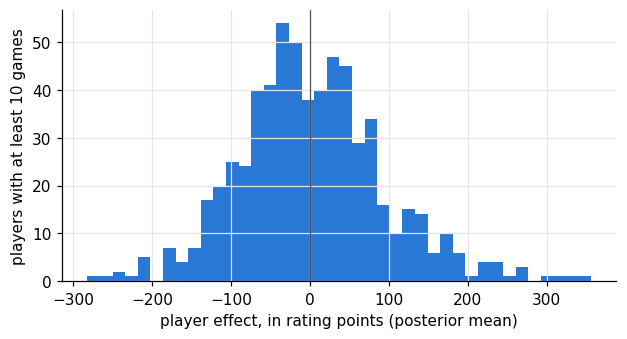

626 players with at least 10 games
stronger than their rating with probability > 0.95: 39
weaker than their rating with probability > 0.95: 34


In [36]:
# player effects of the players with at least 10 games, in rating points
active = player_table[player_table.games >= 10]
points = 400 * active.u_mean / shared.loc["beta, rated games", "mean"]

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(points, bins=40, color=BLUE)
ax.axvline(0, color=GREY, lw=0.8)
ax.set_xlabel("player effect, in rating points (posterior mean)")
ax.set_ylabel("players with at least 10 games")
plt.show()
print(f"{len(active)} players with at least 10 games")
print(f"stronger than their rating with probability > 0.95: {(active.prob_stronger_than_rating > 0.95).sum()}")
print(f"weaker than their rating with probability > 0.95: {(active.prob_stronger_than_rating < 0.05).sum()}")

Players of equal rating differ by $\sigma_p = 0.57$ (0.52 to 0.63), which is about **130 rating points**. Among the 626 players with at least 10 games, 39 are clearly stronger than their rating and 34 clearly weaker. Part 11 shows that this spread partly comes from casual games and from players still at the starting rating of 1500.

# 10 - Does the final model fit the data?

`posterior_predictive_full.py` ran the posterior predictive checks of part 5 again on the final model, from 4,000 simulated data sets.

In [37]:
checks = table("posterior_predictive_full")
checks.pivot(index="statistic", columns="model", values="p_value")[["without player effects", "with player effects"]].pipe(rounded, 3)

model,without player effects,with player effects
statistic,,
"chi-square over deciles of rating gap, all games",0.341,0.548
"chi-square over deciles of rating gap, rated games",0.788,0.809
"chi-square over deciles of rating gap, unrated games",0.199,0.315
"player dispersion, players with at least 10 games",0.000,0.231
sd of white win share between pairs with at least 30 games,0.134,0.123
"white win share, all games",0.499,0.508


With player effects, every check passes, with $p$-values from 0.12 to 0.81: the model reproduces the overall win share, the spread between pairs, the shape of the win share against the rating gap (in all, rated and unrated games), and the dispersion of the players.

# 11 - How much do the answers depend on our choices?

`sensitivity_full.py` refitted the final model 9 times: the baseline, and 8 variants of the priors and of the data:
- the prior on the precisions: half the variance, or much more diffuse;
- a wider prior on $\mu$, and slopes centred on 0 instead of the Elo slope;
- rated games only, no player at the default rating of 1500, draws scored as half a win, and games of at least 20 plies.

In [38]:
sensitivity = table("sensitivity_full").set_index("variant")
show = pd.DataFrame({
    "games": sensitivity["games"],
    "beta rated": sensitivity["beta_rated_mean"],
    "sigma_p": sensitivity["sigma_player_mean"],
    "1.e4 (%)": 100 * sensitivity["p_white_e4_mean"],
    "1.e4 c5 (%)": 100 * sensitivity["p_white_e4_c5_mean"],
    "1.e4 e5 (%)": 100 * sensitivity["p_white_e4_e5_mean"],
    "P(c5 better)": sensitivity["prob_sicilian_better_for_black"],
    "P(e3 below e4)": sensitivity["prob_e3_below_e4"],
    "P(move > reply)": sensitivity["prob_move_matters_more"],
    "largest R-hat": sensitivity["largest_rhat"],
})
show.pipe(rounded, 3)

,games,beta rated,sigma_p,1.e4 (%),1.e4 c5 (%),1.e4 e5 (%),P(c5 better),P(e3 below e4),P(move > reply),largest R-hat
variant,,,,,,,,,,
baseline,17682,1.765,0.575,52.697,50.669,53.604,0.978,0.999,0.892,1.005
"tau Gamma(2, 0.1)",17682,1.763,0.570,52.788,50.598,53.616,0.980,0.999,0.859,1.004
"tau Gamma(0.5, 0.005)",17682,1.766,0.575,52.441,51.125,53.399,0.960,0.993,0.912,1.020
mu sd 1,17682,1.764,0.574,52.708,50.674,53.606,0.978,0.999,0.896,1.008
"beta N(0, 1)",17682,1.757,0.572,52.692,50.670,53.599,0.979,0.999,0.895,1.010
rated games only,14397,1.747,0.438,52.466,50.575,53.511,0.973,0.998,0.883,1.004
no player rated 1500,16394,1.818,0.471,52.275,50.956,53.237,0.942,0.986,0.767,1.008
draws as half wins,18537,1.666,0.438,52.463,50.561,53.336,0.980,0.999,0.899,1.006
at least 20 plies,16741,1.751,0.553,52.094,50.750,53.021,0.939,0.999,0.908,1.005


**What we see:**
- White wins 52.1% to 52.8% after 1.e4 in every variant, the Sicilian is the better reply with probability 0.94 to 0.98, and 1.e3 is worse than 1.e4 with probability at least 0.986. So our main answers do not depend on our choices.
- The claim that the first move matters more than the reply is the most fragile (probability 0.77 to 0.91).
- The player spread is the most sensitive number: it falls from 0.57 to 0.44 on rated games only, and to 0.47 without the players at the possible default rating of 1500 (7.3% of the games). So part of it comes from casual games and provisional ratings.
- Every variant converges ($\hat R$ at most 1.010), except the diffuse prior: under it $\sigma_m$ gets close to zero and the first-move level, which has no rescaling move, mixes slowly ($\hat R$ = 1.020 even with chains four times longer). Its row agrees with the others, but it is only indicative.

# 12 - Do the numbers of the report match the code?

The report never contains a number typed by hand: it reads every number from `report/generated/numbers.tex`, which `make_report_numbers.py` writes from the same tables we use here. As a last check, we recompute in this notebook every number of the report that it quotes, rounded with the same rule, and compare them with that file.

In [39]:
with open("../report/generated/numbers.tex") as f:
    report_numbers = dict(re.findall(r"\\newcommand\{\\(\w+)\}\{(.*)\}", f.read()))


def num(x, digits=2, scale=1):
    """A number written as in the report: the same rounding, with {,} as thousands separator for LaTeX"""
    text = fmt(x, digits, scale).replace(",", "{,}")
    return "$-$" + text[1:] if text.startswith("-") else text


def pct(x, digits=1):
    return num(x, digits, scale=100)


def p_value(p, digits):
    return "<0.001" if p < 0.001 else num(p, digits)


def interval(name, row, digits, scale=1):
    """mean, and the two ends of the 90% interval, as the report names them"""
    return {name: num(row["mean"], digits, scale), name + "Low": num(row["q05"], digits, scale),
            name + "High": num(row["q95"], digits, scale)}


# the tables again, straight from the files
m0 = table("posterior_shared").set_index("quantity")
m0_check = table("posterior_predictive").set_index("statistic")["p_value"]
m1_check = table("posterior_predictive_rating_slopes").set_index(["model", "statistic"])["p_value"]
final = table("posterior_full_shared").set_index("quantity")
first_all = table("posterior_full_first_moves").set_index("first_move")
reply_e4 = table("posterior_full_replies").query("first_move == 'e4'").set_index("reply")
fit_diagnostics = table("sampler_diagnostics_full").set_index("statistic")["value"]
predictive = table("posterior_predictive_full")
dispersion = predictive[predictive.statistic.str.startswith("player dispersion")].set_index("model")
other_checks = predictive[(predictive.model == "with player effects")
                          & ~predictive.statistic.str.startswith("player dispersion")]["p_value"]
repeated = table("validation_full_repeated").set_index("quantity")
variants = table("sensitivity_full").set_index("variant")
fav200 = table("favourite_full").set_index("rating_gap").loc[200]
deciles = "chi-square over deciles of rating gap, "

ours = {
    # Parts 1 to 3, from the raw games
    "nRaw": num(len(games), 0),
    "nDuplicates": num(cleaning.set_index("step").loc["one row per game id", "removed"], 0),
    "nDraws": num(cleaning.set_index("step").loc["decisive result (no draw)", "removed"], 0),
    "nDecisive": num(len(decisive), 0),
    "shareWhiteDecisive": pct(decisive["y"].mean()),
    "shareRated": pct(decisive["rated"].mean()),
    "nPlayers": num(players.nunique(), 0),
    "shareFifteen": pct(((decisive.white_rating == 1500) | (decisive.black_rating == 1500)).mean()),
    "nOpenings": num(len(per_code), 0),
    "medianGamesOpening": num(per_code.median(), 0),
    "nOpeningsOne": num((per_code == 1).sum(), 0),
    "nFirstMoves": num(decisive["first_move"].nunique(), 0),
    "nPairs": num((decisive["first_move"] + " " + decisive["reply"]).nunique(), 0),
    # Part 4, the priors
    "priorWinLow": pct(logistic(-1.96 * 0.5), 0),
    "priorWinHigh": pct(logistic(1.96 * 0.5), 0),
    "priorSpreadLow": num(tau.ppf(0.95) ** -0.5, 2),
    "priorSpreadHigh": num(tau.ppf(0.05) ** -0.5, 2),
    "priorSpreadBelowTenth": pct(tau.sf(0.10 ** -2), 2),
    # Part 5, the path to the final model
    **interval("advantageEco", m0.loc["white advantage in rating points (400 mu / beta)"], 1),
    "pShapeEco": p_value(m0_check["chi-square discrepancy over the bins of rating gap"], 3),
    "pShapeTwoAll": p_value(m1_check[("rated and unrated slopes", deciles + "all games")], 3),
    "pShapeOneRated": p_value(m1_check[("one slope", deciles + "rated games")], 3),
    "pShapeOneUnrated": p_value(m1_check[("one slope", deciles + "unrated games")], 3),
    "dispersionWithout": num(dispersion.loc["without player effects", "observed"], 2),
    "dispersionWithoutLow": num(dispersion.loc["without player effects", "replicated_q05"], 2),
    "dispersionWithoutHigh": num(dispersion.loc["without player effects", "replicated_q95"], 2),
    "pDispersionWithout": p_value(dispersion.loc["without player effects", "p_value"], 2),
    "dispersionWith": num(dispersion.loc["with player effects", "observed"], 2),
    "pDispersionWith": p_value(dispersion.loc["with player effects", "p_value"], 2),
    # Parts 6 to 8, the sampler, its validation and its convergence
    "acceptTheta": num(float(fit_diagnostics["median acceptance rate of theta"]), 2),
    "acceptPlayers": num(float(fit_diagnostics["median acceptance rate of the player effects"]), 2),
    "biasSigmaReply": num(repeated.loc["sigma_reply", "mean_error"], 3),
    "biasSigmaReplySe": num(repeated.loc["sigma_reply", "se_mean_error"], 3),
    "insideSigmaReply": pct(repeated.loc["sigma_reply", "share_inside_90"], 0),
    "biasSigmaMove": num(repeated.loc["sigma_move", "mean_error"], 3),
    "rhatFinal": num(max(float(v) for k, v in fit_diagnostics.items() if "Rhat" in k), 3),
    "essFinalFirstMoves": num(float(fit_diagnostics["smallest ESS, first moves"]), 0),
    # Part 9, the results
    **interval("pWhiteEfour", final.loc["P(white wins) at equal ratings after 1.e4"], 1, 100),
    **interval("advantageEfour", final.loc["white advantage in rating points after 1.e4, rated games (400 gamma / beta)"], 1),
    "probAdvantageEfour": num(final.loc["white advantage in rating points after 1.e4, rated games (400 gamma / beta)",
                                        "prob_positive"], 3),
    "pWhiteDfour": pct(final.loc["P(white wins) at equal ratings after 1.d4", "mean"]),
    "pWhiteEthree": pct(first_all.loc["e3", "p_white_equal_ratings_mean"]),
    "pWhiteEthreeLow": pct(first_all.loc["e3", "p_white_equal_ratings_q05"]),
    "pWhiteEthreeHigh": pct(first_all.loc["e3", "p_white_equal_ratings_q95"]),
    "pWhiteCfour": pct(first_all.loc["c4", "p_white_equal_ratings_mean"]),
    "pWhiteSicilian": pct(reply_e4.loc["c5", "p_white_equal_ratings_mean"]),
    "pWhiteSicilianLow": pct(reply_e4.loc["c5", "p_white_equal_ratings_q05"]),
    "pWhiteSicilianHigh": pct(reply_e4.loc["c5", "p_white_equal_ratings_q95"]),
    "pWhiteOpenGame": pct(reply_e4.loc["e5", "p_white_equal_ratings_mean"]),
    "probSicilian": num(reply_e4.loc["c5", "prob_below_compared"], 3),
    "sigmaMove": num(final.loc["sigma_move (spread between White's first moves)", "mean"], 2),
    "sigmaReply": num(final.loc["sigma_reply (spread between Black's replies to one first move)", "mean"], 2),
    "probMoveMatters": num(final.loc["sigma_move minus sigma_reply", "prob_positive"], 2),
    **interval("betaRated", final.loc["beta, rated games"], 2),
    "eloRatio": num(final.loc["slope of rated games relative to the Elo formula (beta / log 10)", "mean"], 2),
    "betaDiff": num(final.loc["beta, rated minus unrated", "mean"], 2),
    "favouriteTwoHundred": pct(fav200["mean"]),
    "favouriteTwoHundredLow": pct(fav200["q05"]),
    "favouriteTwoHundredHigh": pct(fav200["q95"]),
    "eloTwoHundred": pct(fav200["elo_expected_score"]),
    **interval("sigmaPlayer", final.loc["sigma_player (spread between players at equal rating)"], 2),
    "sigmaPlayerPoints": num(final.loc["sigma_player in rating points, rated games (400 sigma_player / beta)", "mean"], 0),
    # Parts 10 and 11, the fit and the sensitivity
    "pChecksFinalLow": num(other_checks.min(), 2),
    "pChecksFinalHigh": num(other_checks.max(), 2),
    "nVariants": num(len(variants), 0),
    "sensEfourLow": pct(variants["p_white_e4_mean"].min()),
    "sensEfourHigh": pct(variants["p_white_e4_mean"].max()),
    "sensSicilianLow": num(variants["prob_sicilian_better_for_black"].min(), 2),
    "sensSicilianHigh": num(variants["prob_sicilian_better_for_black"].max(), 2),
    "sensEthreeLow": num(variants["prob_e3_below_e4"].min(), 3),
    "sensMoveLow": num(variants["prob_move_matters_more"].min(), 2),
    "sensMoveHigh": num(variants["prob_move_matters_more"].max(), 2),
    "sensPlayerBaseline": num(variants.loc["baseline", "sigma_player_mean"], 2),
    "sensPlayerRatedOnly": num(variants.loc["rated games only", "sigma_player_mean"], 2),
    "sensPlayerNoFifteen": num(variants.loc["no player rated 1500", "sigma_player_mean"], 2),
    "sensRhatOthers": num(variants.drop(index="tau Gamma(0.5, 0.005)")["largest_rhat"].max(), 3),
    "sensRhatDiffuse": num(variants.loc["tau Gamma(0.5, 0.005)", "largest_rhat"], 3),
}
match = pd.DataFrame({"this notebook": ours, "report": {k: report_numbers[k] for k in ours}})
match["same"] = match["this notebook"] == match["report"]
assert match["same"].all(), f"numbers that differ from the report: {list(match.index[~match['same']])}"
print(f"All {len(match)} numbers match the report")
match

All 87 numbers match the report


,this notebook,report,same
nRaw,"20{,}058","20{,}058",True
nDuplicates,945,945,True
nDraws,855,855,True
nDecisive,"17{,}682","17{,}682",True
shareWhiteDecisive,52.1,52.1,True
...,...,...,...
sensPlayerBaseline,0.57,0.57,True
sensPlayerRatedOnly,0.44,0.44,True
sensPlayerNoFifteen,0.47,0.47,True
sensRhatOthers,1.010,1.010,True


Every number we recomputed here is exactly the one in the report, so what we discuss in the report is what the code produces.

# 13 - Conclusion and limitations

**So who controls White's first-move advantage?**

Both players, in a sense. White's first move is worth about **24.5 rating points** after 1.e4 (a win probability of 52.7% at equal ratings), but White can throw it away with a weak first move such as **1.e3** (41.6%), and Black can **almost cancel it with the Sicilian** (50.7%, against 53.6% after 1...e5). These answers hold under every prior and data variant we tried.

On the way, we found two things we did not expect: ratings promise more than they deliver (the stronger player wins less often than the Elo formula says), and players of equal rating differ by about 130 rating points.

**What are the main limitations of our study?**
- **Associations, not causes:** players choose their openings. A player who picks the Sicilian may differ from one who does not in ways that neither the rating nor the player effect capture.
- **The Sicilian contrast:** we noticed it while exploring the data, so its probability of 0.978 should be read with care, even if shrinkage protects against picking chance extremes.
- **The data:** amateur online games from a selection of users, with draws left out (we checked that scoring them as half a win changes nothing important).
- **The prior on the spreads** pulls small spreads up (part 7), so the spreads between openings lean high, and "the first move matters more than the reply" is our most fragile claim.

**What would we do next?**
1. model draws as a third outcome instead of leaving them out;
2. let the strength of a player change over time;
3. use more games, to estimate the rare replies more precisely;
4. use a prior on the spreads that allows small values (for example a half-normal prior on $\sigma$) and add a rescaling move for the first-move level.